In [1]:
#Shishir Khanal
#Aug 21, 2026
#Black Jack RL Agent using MC Control
# Improve Policy until it approaches optimal policy

In [15]:
import numpy as np

class Agent():
    def __init__(self, eps=0.1, gamma=0.99):
        self.Q = {} # Keep track of agent's estimates of values of states
        self.sum_space = [i for i in range(4, 22)] # Possible multiple cards sums for agent
        self.dealer_show_card_space = [i+1 for i in range(10)] #Possible cards in dealer's hand (Ace-Face card(-> 10))
        self.action_space = [0, 1] # Stick/hit
        self.ace_space = [False, True] #Whether player has a usable ace
        
        self.state_space = [] # Track first visit to each state
        self.returns = {} # Track discounted returns after visit to each state
        self.pairs_visited = {} #first visit or not
        self.memory = [] # states encountered and awards received
        
        self.gamma = gamma # discount factor
        self.eps = eps # Exploratory Action hyperparam
        
        self.init_vals()
        self.init_policy()

    def init_vals(self):
        for total in self.sum_space:
            for card in self.dealer_show_card_space:
                for ace in self.ace_space:
                    state = (total, card, ace)
                    self.state_space.append(state)
                    for action in self.action_space:
                        self.Q[(state, action)] = 0
                        self.returns[(state, action)] = [] # returns over each of states over course of all episodes
                        self.pairs_visited[(state, action)] = 0

    def init_policy(self):
        policy = {}
        n = len(self.action_space)
        for state in self.state_space:
            policy[state] = [1/n for _ in range(n)]
        self.policy = policy

    def choose_action(self, state):
        action = np.random.choice(self.action_space, p=self.policy[state])
        return action

    def update_Q(self):
        for idt, (state, action, _) in enumerate(self.memory):
            G = 0
            discount = 1
            if self.pairs_visited[(state, action)] == 0:
                self.pairs_visited[(state, action)] += 1
                for t, (_, _, reward) in enumerate(self.memory[idt:]):
                    G += reward * discount
                    discount *= self.gamma
                    self.returns[(state, action)].append(G)

        for state, action, _ in self.memory:
            self.Q[(state,action)] = np.mean(self.returns[(state, action)])
            self.update_policy(state)

        for state_action in self.pairs_visited.keys():
            self.pairs_visited[state_action] = 0

        self.memory = []

    def update_policy(self, state):
        actions = [self.Q[(state,a)] for a in self.action_space]
        a_max = np.argmax(actions)
        n_actions = len(self.action_space)
        probs = []
        for action in self.action_space:
            prob = 1 - self.eps + self.eps / n_actions if action == a_max else self.eps / n_actions
            probs.append(prob)
        self.policy[state] = probs

In [16]:
import gym
import matplotlib.pyplot as plt

In [19]:
if __name__ == '__main__':
    env = gym.make('Blackjack-v1')
    agent = Agent(eps=0.001)
    n_episodes = 200000
    win_lose_draw = {-1:0, 0:0, 1:0}
    win_rates = []
    for i in range(n_episodes):
        if i>0 and i % 1000 == 0:
            pct = win_lose_draw[1] / i
            win_rates.append(pct)
        if i % 50000 == 0:
            rates = win_rates[-1] if win_rates else 0
            print('starting episode', i, 'win rate %.3f' % rates)
        observation, info = env.reset()
        done = False
        while not done:
            action = agent.choose_action(observation)
            observation_, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            agent.memory.append((observation, action, reward))
            observation = observation_
        agent.update_Q()
        win_lose_draw[reward] += 1

starting episode 0 win rate 0.000
starting episode 50000 win rate 0.408
starting episode 100000 win rate 0.407
starting episode 150000 win rate 0.409


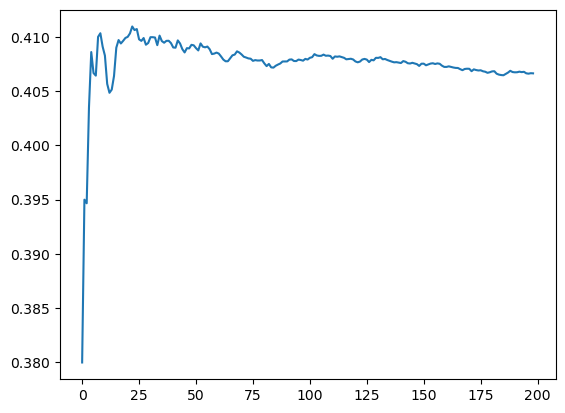

In [18]:
plt.plot(win_rates)
plt.show()